# Ярослав: эксперимент, модели и проверки Scorpion

**Сессия 22 октября 2026 года. Индивидуальный исследовательский отчёт.**

Цель — сопоставить боковые сборки 60, 100 и 140 мм и варианты ТТРКГ 1×1/2×2,
проверить условную двуслойную модель бокового монтажа и перейти к собственной
пространственной КТ/FEM-модели. Ярослав — псевдоним участника.
В сессии имеется 7 записей. Варианты 1×4, ТЕПС, АЕПС и кресты не зарегистрированы.

Дыхательные интервалы и автоматические QRS остаются кандидатными.
Численные результаты являются этапом разработки методики; они не являются
валидированной оценкой функций сердца. Все таблицы по умолчанию свёрнуты.

**Содержание**

1. [Постановка и происхождение входов](#question)
2. [Протокол, электроды и сигналы](#experiment)
3. [Дыхательные уровни и пульсовые циклы](#comparisons)
4. [Отключения и взаимность](#switching)
5. [Сопоставление оборудования](#equipment)
6. [Собственная КТ, Inobitec и руки](#anatomy)
7. [Двуслойная модель боковых сборок](#method)
8. [Пространственная модель и FEM](#fem)
9. [Выводы и воспроизведение](#conclusions)

In [1]:
from pathlib import Path
import sys
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Colab Notebooks/scorpion_v2/subject_report_figures.py').is_file())
sys.path.insert(0,str(root/'Colab Notebooks/scorpion_v2'))
import numpy as np
import pandas as pd
from IPython.display import display,HTML,Image
from plotly.offline import get_plotlyjs
import session_report_figures as F
import subject_report_figures as R
subject='yaroslav'
all_s,all_m,E=F.results()
records=[r for r in all_s['records'] if r['subject']==subject]
levels=[v for v in all_s['levels'] if v['subject']==subject]
profiles=[p for p in all_m['profiles'] if p['subject']==subject]
display(HTML('<style>.jp-Notebook{max-width:1180px;margin:auto;font-size:16px;line-height:1.7}'
 '.jp-RenderedHTMLCommon{font-size:16px;line-height:1.7}'
 '.jp-RenderedHTMLCommon h2{padding-top:16px;border-top:1px solid #cbd5e1}'
 'details{margin:18px 0;border:1px solid #cbd5e1;border-radius:6px;padding:10px 14px;overflow-x:auto}'
 'summary{cursor:pointer;font-weight:600;color:#334155}table{font-size:13px}img{max-width:100%}'
 '@media(max-width:760px){.jp-Notebook{padding:8px}.plotly-graph-div{min-width:960px}}'
 '</style><script>'+get_plotlyjs()+'</script>'))

<a id="question"></a>
## 1. Постановка и происхождение входов

Боковые отведения предназначены для изучения мягких тканей грудной стенки,
кости и лёгкого. Их параметры предполагается использовать как поправку к ТТРКГ.
Переход к эквивалентной сердцу сфере, УО и ФВ требует отдельной прямой модели
и проверки; ЭКГ-синхронности для этого недостаточно.

Измерены общие импедансы и два сигнала ЭКГ. Монтаж и порядок дыхательных проб
подтверждены автором; времена команд прибором не регистрировались.
Тканевые маски лёгких, костей, целого сердца и жира получены автоматически
по собственной КТ и требуют экспертной оценки. Наружная поверхность — собственный
замкнутый STL из Inobitec, выбранный автором для расчёта 26.10.2026.
КТ получена на глубоком вдохе с задержкой по авторскому протоколу.
Она не измеряет геометрическое состояние глубокого выдоха.

Двуслойная модель применяется только к боковым сборкам. ТТРКГ рассчитывается
в пространственной модели с контактами обеих рук. Значения плоских ρ₁, ρ₂
не переносятся в тканевые компартменты FEM автоматически.

<a id="experiment"></a>
## 2. Протокол, электроды и сигналы

Частота зондирования — 100 кГц; ток около 7000 мкА на каждый источник.
Амплитудное или действующее значение и относительная электрическая фаза
источников отдельно не установлены. Рабочая частота дискретизации 1000 Гц
поддержана совпадением TXT и BIN на полной длине каждой записи.
TXT содержит 11 полей; пропусков приращения COUNT по модулю 256 и байтовых
дубликатов в сессии не выявлено. Такая проверка не подтверждает качество физиологии.

Обычный порядок проб: спокойное дыхание → глубокий вдох с задержкой →
усиленное дыхание → глубокий выдох с задержкой. Границы реконструированы
по сигналам и протоколу. В 2×2 используются верхние и нижние контакты
каждой группы на руках; в 1×1 — верхние. Измерительная группа расположена
примерно в 20 мм от плеча, токовая — ещё на 100 мм дальше.
Боковые сборки продольные, справа над рёбрами, с общим центром.

Назначение ТТРКГ по пробам подключения и ЭКГ: второе поле; боковая — первое. Это техническое соответствие полям прибора; основные графики обозначены физическими сборками.

In [2]:
F.show_table(pd.DataFrame([{'Запись':r['record_id'],'Сборки':F.assembly_label(r),'Длительность, с':(r['n']-1)/r['fs'],'Отсчётов':r['n']} for r in records]),'Таблица 1. Состав индивидуальной сессии')

Запись,Сборки,"Длительность, с",Отсчётов
SCV2-Y-001,Боковая 140 мм + ТТРКГ 2×2,72.104,72105
SCV2-Y-002,Только ТТРКГ 2×2,75.852,75853
SCV2-Y-003,Только боковая 140 мм,65.488,65489
SCV2-Y-004,Попеременное отключение: 140 мм и ТТРКГ 2×2,94.565,94566
SCV2-Y-005,Боковая 100 мм + ТТРКГ 2×2,65.462,65463
SCV2-Y-006,Боковая 60 мм + ТТРКГ 2×2,66.448,66449
SCV2-Y-007,Боковая 60 мм + ТТРКГ 1×1,65.511,65512


Для проверки целостности дыхательных проб и связи пульса с ЭКГ рассмотрены полные записи (рисунок 1).

In [3]:
F.show(F.overview('yaroslav'))

**Рисунок 1. Полные записи: общий импеданс, пульсовая полоса и ЭКГ.**

Выбор записи меняет все согласованные панели. Медленная составляющая выделена до 0,5 Гц, пульсовая — в 0,7–12 Гц; исходные отсчёты сохранены. Для длинных кривых прорежено только отображение.

<a id="comparisons"></a>
## 3. Дыхательные уровни и четыре пульсовых цикла

Для сравнения используются внутренние участки задержек, с отступами от
неоднозначных границ. Основной размерный ряд записан при ТТРКГ 2×2;
точка 60 мм при 1×1 служит отдельным сравнением соединения контактов.
Размеры записаны последовательно: время, контакт и физиологическое состояние
могли различаться. Это ограничивает причинную трактовку размерной зависимости.

Размерная зависимость и дыхательное различие абсолютных уровней рассматриваются раздельно для двух отведений (рисунок 2).

In [4]:
F.show(F.levels('yaroslav','lateral'))

**Рисунок 2. Боковая сборка: медианные уровни на глубоком вдохе и выдохе.**

Основной размерный ряд соответствует ТТРКГ 2×2; точка 60 мм при 1×1 относится к отдельному включению. Боковой уровень на вдохе выше уровня на выдохе при всех трёх размерах.

Размерная зависимость и дыхательное различие абсолютных уровней рассматриваются раздельно для двух отведений (рисунок 3).

In [5]:
F.show(F.levels('yaroslav','ttrkg'))

**Рисунок 3. ТТРКГ: медианные уровни на глубоком вдохе и выдохе.**

По оси размера сопоставлены сопутствующие боковые сборки. Точки ТТРКГ при их смене характеризуют межзаписную изменчивость при неизменном монтаже на руках.

Боковые уровни на вдохе и выдохе соответственно: 140 мм — 36.559 / 26.500 Ом; 100 мм — 50.066 / 41.957 Ом; 60 мм — 55.969 / 49.053 Ом. Во всех трёх парах уровень на вдохе выше; это наблюдение в кандидатных окнах, не сопротивление отдельной ткани.

In [6]:
F.show_table(pd.DataFrame([{'Сборка':F.ROLE[v['role']],'Размер боковой, мм':v['size_mm'],'ТТРКГ':v['variant'],'Дыхание':F.STATE[v['state']],'Медиана, Ом':v['baseline_ohm'],'Циклов':v['n_candidate_cycles'],'Размах медианного цикла, мОм':v['median_curve_ptp_mohm']} for v in levels if v['kind']=='both']),'Таблица 2. Уровни и число полных кандидатных циклов')

Сборка,"Размер боковой, мм",ТТРКГ,Дыхание,"Медиана, Ом",Циклов,"Размах медианного цикла, мОм"
ТТРКГ,140,2x2,Глубокий вдох,48.96,9,152.12
Боковая сборка,140,2x2,Глубокий вдох,36.559,9,149.55
ТТРКГ,140,2x2,Глубокий выдох,48.358,9,148.49
Боковая сборка,140,2x2,Глубокий выдох,26.5,9,44.89
ТТРКГ,100,2x2,Глубокий вдох,47.759,9,141.74
Боковая сборка,100,2x2,Глубокий вдох,50.066,9,156.51
ТТРКГ,100,2x2,Глубокий выдох,47.139,6,155.5
Боковая сборка,100,2x2,Глубокий выдох,41.957,6,72.605
ТТРКГ,60,2x2,Глубокий вдох,47.331,7,142.61
Боковая сборка,60,2x2,Глубокий вдох,55.969,7,108.04


Четыре последовательных цикла ограничены пятью кандидатами QRS. Выбор не основан на амплитуде импеданса. Участки выровнены по первому QRS, длительность и амплитуда сохранены; в нижней панели показана ЭКГ. Автоматические события ещё не приняты вручную.

Для сравнения амплитуды и временной формы без нормировки длительности выбраны четыре последовательных цикла (рисунок 4).

In [7]:
F.show(F.cycle_plot('yaroslav','lateral'))

**Рисунок 4. Боковая сборка: четыре цикла на вдохе при боковых 140/100/60 мм.**

Показаны все отсчёты выбранных участков. Привязка к ЭКГ задаёт временной ориентир и не доказывает сердечное происхождение каждого колебания импеданса.

Для сравнения амплитуды и временной формы без нормировки длительности выбраны четыре последовательных цикла (рисунок 5).

In [8]:
F.show(F.cycle_plot('yaroslav','ttrkg'))

**Рисунок 5. ТТРКГ: четыре цикла на вдохе при боковых 140/100/60 мм.**

Показаны все отсчёты выбранных участков. Привязка к ЭКГ задаёт временной ориентир и не доказывает сердечное происхождение каждого колебания импеданса.

Для сравнения амплитуды и временной формы без нормировки длительности выбраны четыре последовательных цикла (рисунок 6).

In [9]:
F.show(F.cycle_plot('yaroslav',"ttrkg",variants=True))

**Рисунок 6. ТТРКГ 1×1 и 2×2: отдельное пульсовое сравнение при боковой 60 мм.**

Соответствующие позиции контактов сохранены, менялось объединение площадок. Последовательная регистрация не исключает различие контакта и состояния.

Сравнение в общей фазе позволяет отдельно рассмотреть медианную форму при разных длительностях циклов (рисунок 7).

In [10]:
F.show(F.ensemble_plot('yaroslav'))

**Рисунок 7. Медианные кандидатные циклы в фазе QRS–QRS.**

Для этого представления каждый цикл приведён к 200 фазовым точкам и удалён его средний уровень. Медианная форма отличается от медианы отдельных размахов; нормировка времени не используется в графиках четырёх циклов.

<a id="switching"></a>
## 4. Отключения и проверка взаимности

В пробе попеременного отключения разъём вынимали из прибора; электроды
оставались на теле. По подтверждению автора на всём протяжении пробы
удерживался глубокий вдох. Это не исключает движения и контактных переходов.
Числа отключённого тракта около 4,6/6,4 Ом не интерпретируются как физиология.
Изменение активного отведения не устанавливает механизм межканального влияния.

In [11]:
F.show_table(pd.DataFrame([{'Состояние':v['state'],'Начало, с':v['start_s'],'Конец, с':v['end_s'],'ТТРКГ, Ом':v['ttrkg_median_ohm'],'Боковая, Ом':v['lateral_median_ohm']} for v in all_s['switching'] if v['subject']==subject]),'Таблица 3. Участки пробы отключения')

Состояние,"Начало, с","Конец, с","ТТРКГ, Ом","Боковая, Ом"
both,5,11,47.26,30.875
ttrkg_only,21,32,47.505,6.6921
both,41,44,47.516,32.026
lateral_only,55,65,4.6041,31.891
both,78,89,48.013,32.226


Отдельной записи с перестановкой токовой и измерительной пар в этой сессии нет.

<a id="equipment"></a>
## 5. Сопоставление оборудования

В проверенном манифесте сопоставимой серии МГТУ записей этого участника нет. Межприборное сравнение не рассчитано; записи другого человека вместо них не используются.

<a id="anatomy"></a>
## 6. Собственная поверхность Inobitec и руки обхватом 37 см

Наружный контур задан собственным замкнутым STL в LPS и миллиметрах.
Автоматический HU-контур рассматривается как отдельная диагностическая
постановка и не подменяет выбранную автором поверхность.
Новые цилиндры имеют радиус 370/(2π)=58,887 мм. Полное круговое сечение
каждой руки погружается в туловище с зазором 0,15 мм; стык выбирается
по минимуму геометрического смещения в объявленной области поиска.
Это геометрическое допущение, не измеренный плечевой ориентир.

Боковой центр соответствует рабочему смещению −15 мм по Y, то есть вперёд,
с сохранением высоты. Кожная кривая и контакты заново построены на собственном
ручном STL. Численная величина смещения и длина сборки по кожной дуге
являются сценариями. Номинальные контакты — диски диаметром 5 мм.
Полная электродная модель (CEM) представляет площадку эквипотенциальным
проводником с заданным контактным импедансом на границе с тканью.

На рисунке 8 показана собственная расчётная поверхность с новыми руками и центрами контактов.

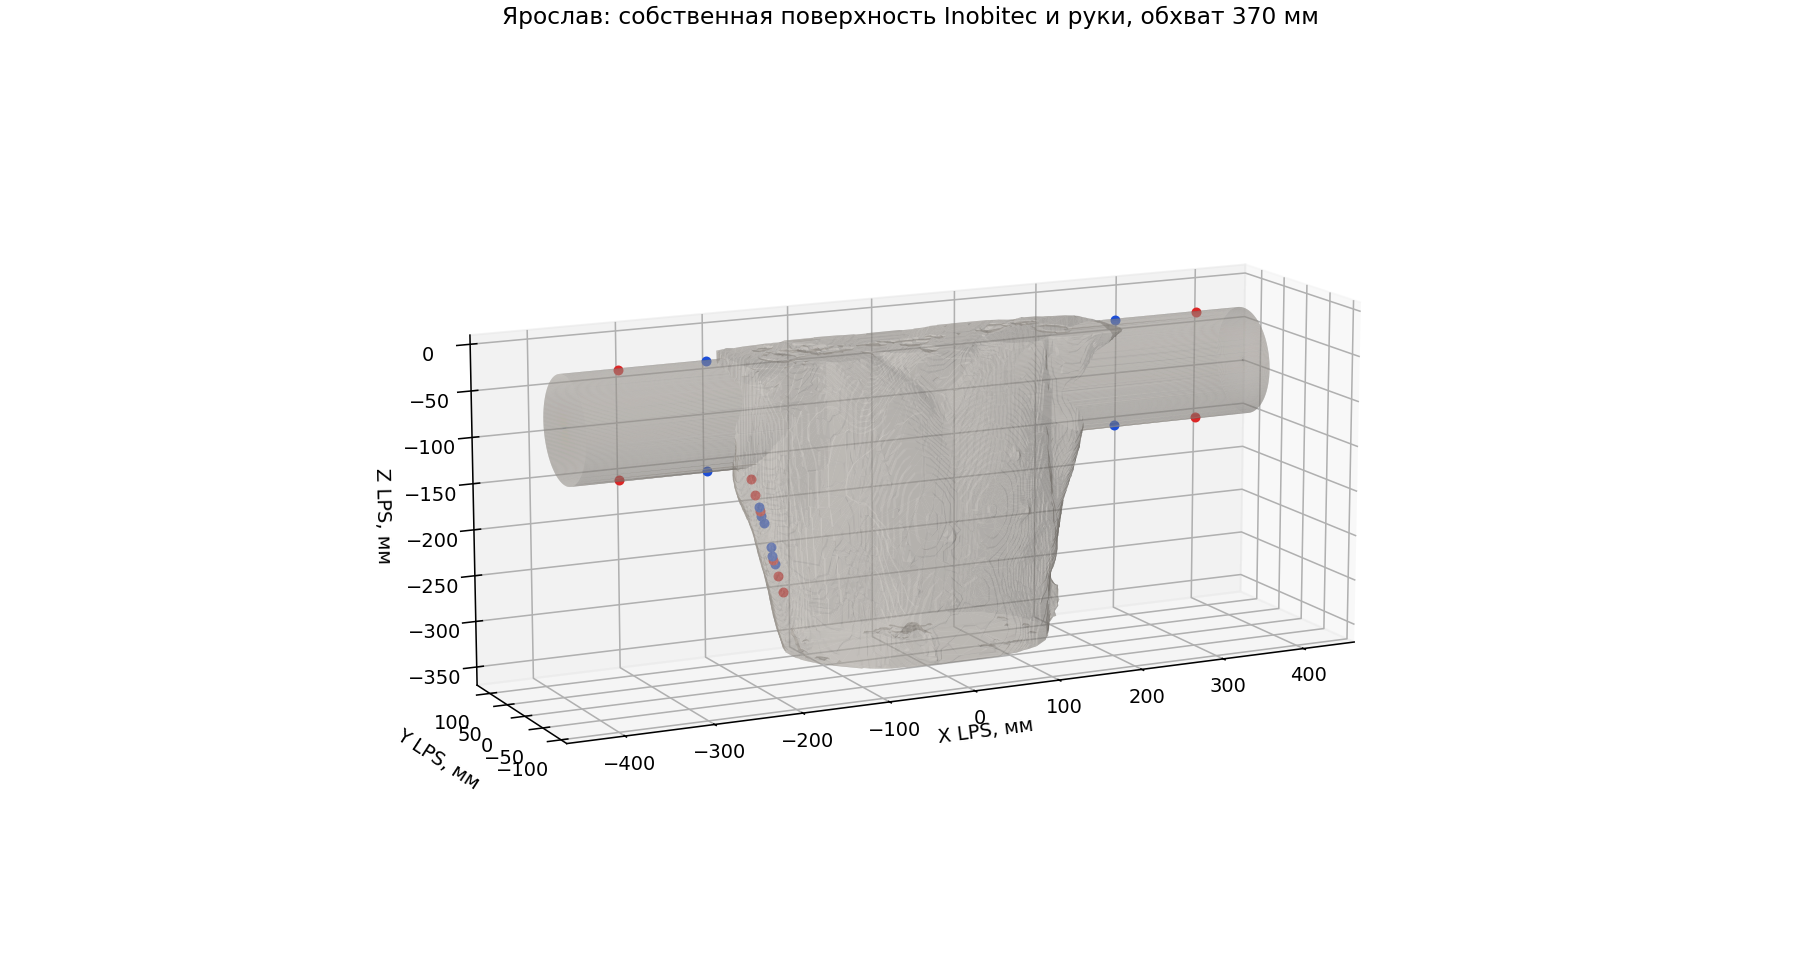

In [12]:
cfg,placement,geometry_qc=R.geometry(subject)
display(Image(filename=str(R.geometry_image(subject))))

**Рисунок 8. Ярослав. Собственная поверхность Inobitec, новые руки и центры контактов.**

Поверхность упрощена только при построении изображения. Красные точки — токовые, синие — измерительные центры; экранный маркер не задаёт площадь CEM. Все три альтернативных боковых размера показаны для локализации; в одной FEM-схеме присутствуют только контакты фактически выбранного размера.

In [13]:
F.show_table(pd.DataFrame([{'Рука':'Правая' if cfg['synthetic_cylinders'][i]['direction']<0 else 'Левая','Стык X, мм':v['x_mm'],'Центр Y/Z, мм':str(v['centre_yz_mm']),'Заглубление, мм':v['inset_mm'],'Покрытие кругового сечения':v['cross_section_covered_fraction']} for i,v in enumerate(placement['joins'])]),'Таблица 4. Индивидуальные стыки новых цилиндров')

Рука,"Стык X, мм","Центр Y/Z, мм","Заглубление, мм",Покрытие кругового сечения
Правая,-175.5,"[24.037328944001274, -75.96180481592307]",49.5,1
Левая,149.5,"[35.537328944001274, -76.03732894400127]",75.5,1


In [14]:
F.show_table(pd.DataFrame([{'Маска':name,'Вокселей':v['total_mask_voxels'],'Вне ручной области':v['outside_after'],'Доля вне области':v['outside_after']/v['total_mask_voxels']} for name,v in geometry_qc['tissue_coverage'].items()]),'Таблица 5. Согласование автоматических тканевых масок с ручной областью')

Маска,Вокселей,Вне ручной области,Доля вне области
lung,5032465,0,0
bone,1606890,30590,0.019037
heart,631925,0,0
fat,1387158,12206,0.0087993


Лёгкое и сердце полностью покрыты ручной областью. Часть кандидатных масок кости и жира находится вне неё и сохраняется в таблице как расхождение источников. Для новой области задан технический сценарий покрытия: до 5% вокселей каждой из этих двух масок могут оставаться вне расчётного тела; это не оценка точности сегментации. Исходные маски не удалены и не исправлены. FEM использует их пересечение с выбранной расчётной областью.

От выбранной ручной кожи рассчитаны лучи по LPS +X до первого пересечения правого лёгкого в собственной воксельной маске. Начало луча берётся на STL без вокселизации; граница лёгкого — на уровне 0,49 бинарной маски. Это заданное направление внутрь грудной клетки, не нормаль к коже и не направление электрической чувствительности.

Пространственная неоднородность участка до лёгкого проверяется вдоль всей длины сборки (рисунок 9).

In [15]:
F.show(R.ct_profile(subject))

**Рисунок 9. Профиль от ручной кожи до первого правого лёгкого при рабочем смещении −15 мм.**

Толщина меняется вдоль размера сборки. Вертикальные линии обозначают A–M–N–B для 140 мм по кожной дуге. Ни центральное значение, ни медиана профиля не принимаются как эффективная h двуслойной модели: способ такого сведения ещё требует проверки относительно FEM.

В пределах 140 мм длина луча меняется от 29.05 до 72.46 мм; медиана 45.93 мм. Это разброс вдоль одной линии, без охвата всей площади сборки и без оценки ошибки сегментации.

In [16]:
F.show_table(pd.DataFrame(__import__('audit_scorpion_session').read(R.model_root(subject)/'ct_profile.local.json')['summaries']).rename(columns={'size_mm':'Размер, мм','ray_count':'Лучей','minimum_depth_mm':'Минимум, мм','median_depth_mm':'Медиана, мм','maximum_depth_mm':'Максимум, мм'}),'Таблица 6. Разброс расстояний до первого лёгкого вдоль трёх сборок')

"Размер, мм",Лучей,"Минимум, мм","Медиана, мм","Максимум, мм"
60,109,39.927,45.927,54.548
100,181,32.79,45.927,62.563
140,253,29.048,45.927,72.458


<a id="method"></a>
## 7. Двуслойная модель боковых сборок

Наружный слой имеет эффективные h и ρ₁, внутренний — ρ₂. Оба слоя изотропны,
граница плоская, боковая область полубесконечна. ТТРКГ и её источник в это
сокращение не входят. Центры A–M–N–B заданы как −L/2, −L/4, L/4, L/2;
ток и напряжение усредняются по конечным дискам диаметром 5 мм.
Контактная эквипотенциальность CEM в аналитической модели не описана.

$$G(r)=\frac{\rho_1}{2\pi}\left[\frac1r+2\sum_{n=1}^{256}
\frac{k^n}{\sqrt{r^2+(2nh)^2}}\right],\qquad
k=\frac{\rho_2-\rho_1}{\rho_2+\rho_1}.\tag{1}$$

Длины выражены в метрах, ρ — в Ом·м. Комбинация потенциалов даёт импеданс
в Ом. При каждой h из ряда 5, 10, 15, 20, 30, 40, 50, 60, 80, 100, 120,
150 мм заново подбираются два сопротивления по трём размерам. Следовательно,
перебор h — набор разных обратных задач; h=120 мм — одна фиксированная
геометрия. Сетка толщин не является КТ-измерением или доверительным интервалом.

Вдох и выдох подбираются раздельно. Границы ρ взяты из рабочего профиля
100 кГц сохранённого литературного реестра на основе IT'IS V5.0 [1, 2];
они включают смешанные низкочастотные данные
и не являются индивидуальными нормами. Минимальная невязка не доказывает
анатомическую толщину.

Повторный подбор при каждой толщине показывает зависимость сопротивлений и невязки от h (рисунок 10).

In [17]:
F.show(F.two_layer_profile('yaroslav'))

**Рисунок 10. Невязка и условные сопротивления при отдельных фиксированных h.**

Оба минимума находятся при 5 мм: 2,823 Ом на вдохе и 3,298 Ом на выдохе. Граница сетки и граница сопротивления не принимаются как анатомический результат.

In [18]:
F.show_table(pd.DataFrame([{'Дыхание':F.STATE[p['state']],'h, мм':p['h_mm'],'ρ₁, Ом·м':p['rho_ohm_m'][0],'ρ₂, Ом·м':p['rho_ohm_m'][1],'RMSE, Ом':p['rmse_ohm'],'Обусловленность по log ρ':p['condition_log_rho'],'Параметры на границе':str(p['boundary_parameters']),'RMSE пульса, мОм':p['pulse']['joint_rmse_mohm'] if p['pulse'] else None} for p in profiles]),'Таблица 7. Условные статические и пульсовые решения')

Дыхание,"h, мм","ρ₁, Ом·м","ρ₂, Ом·м","RMSE, Ом",Обусловленность по log ρ,Параметры на границе,"RMSE пульса, мОм"
Глубокий вдох,5,1.3774,9.201,2.8229,5.4954,[1],3.5024
Глубокий вдох,10,2.2722,11.094,2.8284,5.8724,[],3.8471
Глубокий вдох,15,2.8791,13.444,3.1874,7.0444,[],4.3274
Глубокий вдох,20,3.2203,18.448,3.5684,10.186,[],5.0314
Глубокий вдох,30,3.812,24.074,4.7066,17.061,[2],5.9868
Глубокий вдох,40,4.1666,24.074,6.3047,25.067,[2],6.6525
Глубокий вдох,50,4.3461,24.074,7.45,37.208,[2],7.1707
Глубокий вдох,60,4.4436,24.074,8.1894,54.167,[2],7.5575
Глубокий вдох,80,4.5349,24.074,8.9786,105.9,[2],8.0588
Глубокий вдох,100,4.5723,24.074,9.3366,187.38,[2],8.3464


Кандидатные циклы сначала ограничиваются QRS, затем каждый приводится
к 200 фазовым точкам и из него вычитается средний уровень. В каждой фазе
берётся медиана по циклам. Это построение медианной формы не оценивает
долю сердечного источника.

В каждой базовой точке рассчитывается якобиан
$J_{Lj}=\partial Z_L/\partial\log\rho_j$. Линейная пульсовая инверсия задаётся
$\Delta Z(\varphi)\approx J\Delta\log\rho(\varphi)$ и решается методом
наименьших квадратов. Для проверки один пульсовой размер исключается,
два остальных определяют возмущения; затем предсказывается оставленная кривая.
Базовые ρ уже подогнаны по всем трём статическим уровням, поэтому эта проверка
независима только от исключённой пульсовой кривой.

В примере h=120 мм малость возмущения по предварительному критерию
максимального модуля Δlogρ менее 0,1 на вдохе не подтверждена.
Прямая нелинейная проверка этих возмущений не выполнена.

Проверка на исключённом пульсовом размере показывает способность двух остальных размеров предсказывать его кривую (рисунок 11).

In [19]:
F.show(F.pulse_prediction('yaroslav',120))

**Рисунок 11. Пульсовой прогноз оставленного размера по двум другим при h=120 мм.**

Сплошная кривая — медианный цикл, пунктир — условный прогноз. Расхождение формы и амплитуды не исправлялось произвольным знаком или масштабом. Это проверка внутри размерного ряда, не внешняя валидация.

Для выдоха условный пульсовой расчёт также сохранён в таблице; его статус и ограничения совпадают с описанными для вдоха.

<a id="fem"></a>
## 8. Пространственная модель ТТРКГ и боковых сборок

Сетка строится заново на собственной ручной поверхности с новыми руками.
Изменение наружного контура контролируется отдельно от формы тетраэдров.
Проверяются положительные объёмы, качество элементов, фактическая граница
и проекция контактов. Для дисков 5 мм CEM требует ошибки площади менее 12%,
смещения центроида менее 1 мм, протяжённости менее 3,7 мм и отсутствия
общих узлов разных площадок. Контактный импеданс 0,01 Ом·м² — рабочее
неизмеренное условие. Успех генератора сетки сам по себе не подтверждает CEM.

Тканевые доли интегрируются по собственной КТ на вложенных наборах
1024 и 4096 проб Соболя. Материалы: мягкотканный фон, лёгкое, кость,
целое сердце, жир. В искусственных продолжениях за пределами КТ принят
мягкотканный фон. Электрический оператор собирается каноническими EIDORS-
процедурами проекта; индивидуальные материальные матрицы собираются заново.
Проводимость тетраэдра задаётся суммой объёмных долей, делённых на ρ
соответствующих тканей. Используется вещественная скалярная изотропная
проводимость; анизотропия и диэлектрическая часть здесь не описаны.

Основной оператор — передача от собственного источника каждого монтажа.
Дополнительно рассчитываются перекрёстные передачи. Неизвестная относительная
фаза двух источников не подменяется подтверждённым одновременным режимом.
При 1×1 нижние площадки в основном сценарии оставлены индивидуально плавающими;
их физическое присутствие не установлено независимо.

Состояние стадий показано на момент построения данного отчёта.
Незавершённый этап не считается выполненным по наличию входного файла.

In [20]:
F.show_table(R.model_state(subject),'Таблица 8. Состояние подготовки и прямого FEM')

Этап,Состояние,Причина отказа
Наружная поверхность и руки,Подготовлено,
Объёмная сетка,Выполняется,
Тканевые доли 1024/4096,Ожидает входов,
Вход конечных контактов,Ожидает входов,
Конечные CEM-площадки,Ожидает входов,
Прямой FEM,Ожидает входов,


In [21]:
F.show_table(R.literal_tissues(subject),'Таблица 9. Литературный сценарий при 100 кГц')

Компартмент,"Вдох, Ом·м","Выдох, Ом·м"
Мягкотканный фон: мышца,2.7636,2.7636
Лёгкое,9.3153,3.6817
Кость: кортикальная,48.098,48.098
Целое сердце: миокардиальный сценарий,4.6488,4.6488
Жир,23.041,23.041


Для фона использована мышца, для костей — кортикальная ткань, для целой маски сердца — миокардиальный сценарий эффективного компартмента. Он не разделяет кровь и миокард и не задаёт измеренную долю крови. Между вдохом и выдохом в опорном сценарии меняется сопротивление лёгкого; геометрическое дыхательное движение не моделируется.

**Завершённого прямого FEM-результата на момент экспорта нет.** В таблице стадий сохранено текущее состояние или точная причина отказа. Импедансы, чувствительности и параметры сердца без завершённого решения не показываются.

<a id="conclusions"></a>
## 9. Выводы и воспроизведение

Размерные уровни и пульсовые кривые получены из собственных записей Scorpion.
Условная двуслойная модель обнаруживает зависимость параметров от заданной h
и ограничения пульсовой линеаризации. Она не устанавливает анатомическую
толщину и не переносится на ТТРКГ.

Ручной STL определяет индивидуальную наружную область, а руки перестроены
под обхват 37 см. Геометрическое размещение, контактный импеданс и свойства
тканей сохраняют статус сценариев. Численный контроль пространственной модели
нужен перед совместным подбором ρ₁–ρ₄ и эквивалентной замены сердца.
Функции сердца в данном отчёте не определены.

Воспроизведение использует исходные TXT/BIN, собственные КТ и маски,
локальные конфигурации и сохранённые результаты. Обработку сигналов выполняет
`session_20261022.py`, боковую двуслойную задачу — `session_two_layer.py`.
Ручную геометрию и сетку готовит `scorpion_session_prepare.py` через единый
`prepare_ct_fem.py`; электрический вход — `scorpion_session_electrical_inputs.py`.
FEM выполняется профилем `scorpion_session_fem` в `run_pipeline.m`.
Этот ноутбук только читает результаты и не запускает дорогие задачи.
HTML не содержит исходного кода; формулы могут требовать загрузки MathJax.

## Источники параметров

1. IT'IS Foundation. *Tissue Properties Database V5.0*. 2025.
   DOI: 10.13099/VIP21000-05-0.
   [Официальная страница версии](https://itis.swiss/virtual-population/tissue-properties/downloads/database-v5-0).
2. [Сохранённый реестр тканей проекта](../../MATLAB_TRKG4_real_subjects/configs/tissue_literature_v2.json),
   `itis_v5_tissue_reference_20260916_v2`. Из него взяты частотные значения
   модели Gabriel при 100 кГц и рабочие границы поиска. Хэш реестра связан
   с расчётными паспортами. Официальная страница подтверждает версию базы;
   индивидуальные значения тканей она не устанавливает.